<a href="https://colab.research.google.com/github/iansmena/Inteligencia-Artificial---Practicas/blob/main/Practica02_Preprocesamiento_de_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practica 2: Procesamiento de Datos
**Inteligencia Artificial — 6to Nivel**

**Estudiante:** Ian Sebastián Mena

**Docente:** Rodrigo Tufiño

**Fecha:** 16/10/2026

Celda de verificación: ejecutar antes de iniciar.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt
print("✅ Todas las librerías cargadas correctamente")

✅ Todas las librerías cargadas correctamente


# FASE 1. Anatomía de un Dataset

Dataset de estudiantes. Ejecuta el siguiente bloque. No lo modifiques nada todavía, solo léelo con atención.

In [ ]:
import numpy as np
import pandas as pd

datos = {
    "nombre":        ["Ana",  "Luis", "María", "Carlos", "Sofía", "Diego"],
    "edad":          [21,     23,     20,      25,       22,      21],
    "promedio_gpa":  [8.9,    7.4,    9.5,     6.1,      8.2,     7.8],
    "horas_estudio": [18,     10,     22,      6,        15,      12],
    "distancia_km":  [2.5,    15.0,   0.8,     40.2,     5.1,     8.7],
    "carrera":       [
        "Computación","Computación","Redes","Redes","Computación","Redes"],
    "nivel_ingles":  [
        "Básico", "Intermedio","Avanzado","Básico","Avanzado","Intermedio"],
    "beca":          [1,      0,      1,       0,        1,       0],
    "aprobado":      ["Sí",   "No",   "Sí",    "No",     "Sí",    "No"]
}

df = pd.DataFrame(datos)
print(df)
print(f"\nDimensiones del dataset: {df.shape}")

   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computación   
2   María    20           9.5             22           0.8        Redes   
3  Carlos    25           6.1              6          40.2        Redes   
4   Sofía    22           8.2             15           5.1  Computación   
5   Diego    21           7.8             12           8.7        Redes   

  nivel_ingles  beca aprobado  
0       Básico     1       Sí  
1   Intermedio     0       No  
2     Avanzado     1       Sí  
3       Básico     0       No  
4     Avanzado     1       Sí  
5   Intermedio     0       No  

Dimensiones del dataset: (6, 9)


## Actividad 1.1:

### Identifica la estructura. Responde en tu notebook como comentarios o celdas Markdown:

**P1. ¿Cuántas instancias (filas) tiene este dataset? ¿Qué representa cada instancia en el mundo real?**

*Respuesta:*  El dataset cuenta con 6 instancias. Cada una representa un estudiante.

**P2. Lista todos los atributos (columnas). Ahora sepáralos en dos grupos: ¿cuáles actuarían como features y cuál sería el label si tu objetivo fuera predecir si un estudiante aprueba o no?**

*Respuesta:*
Features: nombre, edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca.

Label: aprobado.

**P3. La columna nombre es un atributo, pero ¿debería ser un feature para un modelo de ML? ¿Por qué sí o por qué no?**

*Respuesta:* No, no debería estar, al no dar información valiosa, deberia ser una variable identificadora.

## Actividad 1.2:

### Clasifica las variables. Completa la siguiente tabla en tu notebook. Para cada columna, indica su tipo según los criterios estudiados en clase:

In [ ]:
clasificacion = {
    "columna":        ["edad", "promedio_gpa", "horas_estudio", "distancia_km",
                       "carrera", "nivel_ingles", "beca", "aprobado"],
    "cuantitativa_o_cualitativa": ["cuantitativo", "cuantitativo", "cuantitativo", "cuantitativo", "cualitativo", "cualitativo", "cualitativo", "cualitativo"],
    "discreta_o_continua":        ["discreta", "continua", "continua", "continua", "N/A", "N/A", "N/A", "N/A"],
    "nominal_u_ordinal":          ["NA","NA","NA","NA","nominal", "ordinal", "nominal", "nominal"]
}
df_tipos = pd.DataFrame(clasificacion)
print(df_tipos)

         columna cuantitativa_o_cualitativa discreta_o_continua  \
0           edad               cuantitativo            discreta   
1   promedio_gpa               cuantitativo            continua   
2  horas_estudio               cuantitativo            discreta   
3   distancia_km               cuantitativo            discreta   
4        carrera                cualitativo                 N/A   
5   nivel_ingles                cualitativo                 N/A   
6           beca                cualitativo                 N/A   
7       aprobado                cualitativo                 N/A   

  nominal_u_ordinal  
0                NA  
1                NA  
2                NA  
3                NA  
4           nominal  
5           ordinal  
6           nominal  
7           nominal  


**P4. nivel_ingles tiene los valores Básico, Intermedio y Avanzado. ¿Es nominal u ordinal? ¿En qué te basas para decidirlo? ¿Importa esa distinción a la hora de entrenar un modelo?**

*Respuesta:* nivel_ingles es ordinal. Esto debido a que los niveles de ingles tienen un orden jerarquico. Si importa.

**P5. La columna beca solo contiene 0 y 1. ¿Es cuantitativa discreta o cualitativa nominal? Justifica tu respuesta. Pista: piensa en si tiene sentido calcular la media de esos valores.**

*Respuesta:* beca es cualitativa nominal, esto debido a que la respuesta es "Si" o "No", por lo cual no existe un orden jerarquico del mismo.

## Actividad 1.3:

### Inspeccionando tipos de datos.

In [ ]:
print("Tipos de datos detectados por pandas:")
print(df.dtypes)
print("\nEstadísticas descriptivas (solo numéricas):")
print(df.describe())

Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas (solo numéricas):
            edad  promedio_gpa  horas_estudio  distancia_km      beca
count   6.000000      6.000000       6.000000       6.00000  6.000000
mean   22.000000      7.983333      13.833333      12.05000  0.500000
std     1.788854      1.192337       5.741661      14.68615  0.547723
min    20.000000      6.100000       6.000000       0.80000  0.000000
25%    21.000000      7.500000      10.500000       3.15000  0.000000
50%    21.500000      8.000000      13.500000       6.90000  0.500000
75%    22.750000      8.725000      17.250000      13.42500  1.000000
max    25.000000      9.500000      22.000000      40.20000  1.000000


**P6. ¿Coinciden los tipos que detecta pandas (int64, object, float64) con tu clasificación teórica de la actividad 1.2? Señala al menos un caso donde no coincidan y explica por qué pandas puede estar "equivocado" desde la perspectiva conceptual.**

*Respuesta:* beca esta "mal". Pandas no tiene el contexto previo de beca por lo cual, al ver que puede ser 1 o 0, lo representa como numerico.

**P7. Observa las estadísticas descriptivas. ¿Qué columna tiene mayor dispersión (std)? ¿Qué problema podría ocasionar esa diferencia de escala si alimentas este dataset directamente a un algoritmo como KNN?**

*Respuesta:* distancia_km tiene mayor dispersión. Quizas podria alimentar la logica de que los estudiantes que toman Redes, viven más lejos.

# FASE 2. Escalado con NumPy

En esta fase implementarás los algoritmos desde cero usando solo NumPy. El objetivo es que entiendas exactamente qué hace cada transformación antes de usar una librería que la oculte.

## Actividad 2.1:

### Preparando los datos

In [ ]:
# Extraemos SOLO las columnas numéricas continuas para esta fase
columnas_numericas = ["promedio_gpa", "horas_estudio", "distancia_km"]
X = df[columnas_numericas].values.astype(float)

print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape} → {X.shape[0]} instancias, {X.shape[1]} features")

Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3) → 6 instancias, 3 features


**P8. ¿Por qué excluimos edad y beca de esta matriz aunque también son numéricas? ¿Tiene sentido escalar la columna beca que solo contiene 0 y 1?**

*Respuesta:* edad y beca se excluyeron porque aunque son numericas no son continuas. No, porque no muestra datos numericos que puedan ser evaluados.

## Actividad 2.2:

### Normalización Min-Max

In [ ]:
def min_max_manual(X):
    """
    Normalización Min-Max: transforma cada columna al rango [0, 1]
    Fórmula: x' = (x - min) / (max - min)
    """
    X_min = X.min(axis=0)   # mínimo por columna
    X_max = X.max(axis=0)   # máximo por columna
    X_norm = (X - X_min) / (X_max - X_min)
    return X_norm, X_min, X_max

X_minmax, mins, maxs = min_max_manual(X)

print("=== RESULTADO MIN-MAX ===")
print(f"{'Feature':<18} {'Min original':>14} {'Max original':>14}")
print("-" * 48)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {mins[i]:>14.2f} {maxs[i]:>14.2f}")

print("\nDatos normalizados (Min-Max):")
df_minmax = pd.DataFrame(X_minmax, columns=[c+"_mm" for c in columnas_numericas])
print(df_minmax.round(4))

=== RESULTADO MIN-MAX ===
Feature              Min original   Max original
------------------------------------------------
promedio_gpa                 6.10           9.50
horas_estudio                6.00          22.00
distancia_km                 0.80          40.20

Datos normalizados (Min-Max):
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005


**P9. Después de aplicar Min-Max, ¿cuál es el valor mínimo y máximo que puede tomar cualquier columna? Verifica que tus resultados lo confirmen. ¿Qué representa un valor transformado de 0.0? ¿Y uno de 1.0?**

*Respuesta:* el valor minimo es 0.0 y el maximo es 1.0. el valor transformado de 0.0 representa el valor mas bajo, mientras que el 1.0 representa el valor mas alto.

**P10. Fíjate en la columna distancia_km. Carlos vive a 40.2 km, que es un valor extremo. Ahora imagina que llega un nuevo estudiante que vive a 80 km. Si agregas ese dato y vuelves a normalizar, ¿qué le pasará al valor transformado de todos los demás estudiantes? ¿Es eso un problema? ¿Por qué?**

*Respuesta:* el valor transformado de los estudiantes bajarian aun mas, teniendo en cuenta que 80 seria el nuevo Max. Es un problema porque al existir una normalizacion previa, el nuevo valor invalidaria la realidad de los valores, porque no los estan evaluando en su forma base.

## Actividad 2.3:

### Estandarización Z-Score

In [ ]:
def zscore_manual(X):
    """
    Z-Score: transforma cada columna a media=0 y desv.est.=1
    Fórmula: z = (x - media) / desviacion_estandar
    """
    media = X.mean(axis=0)
    std   = X.std(axis=0)        # desviación estándar de la población
    X_z   = (X - media) / std
    return X_z, media, std

X_zscore, medias, stds = zscore_manual(X)

print("=== RESULTADO Z-SCORE ===")
print(f"{'Feature':<18} {'Media':>10} {'Desv.Est.':>12}")
print("-" * 42)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {medias[i]:>10.3f} {stds[i]:>12.3f}")

print("\nDatos estandarizados (Z-Score):")
df_z = pd.DataFrame(X_zscore, columns=[c+"_z" for c in columnas_numericas])
print(df_z.round(4))

=== RESULTADO Z-SCORE ===
Feature                 Media    Desv.Est.
------------------------------------------
promedio_gpa            7.983        1.088
horas_estudio          13.833        5.241
distancia_km           12.050       13.407

Datos estandarizados (Z-Score):
   promedio_gpa_z  horas_estudio_z  distancia_km_z
0          0.8422           0.7950         -0.7123
1         -0.5359          -0.7314          0.2200
2          1.3934           1.5581         -0.8391
3         -1.7303          -1.4945          2.0997
4          0.1991           0.2226         -0.5184
5         -0.1684          -0.3498         -0.2499


**P9. Después de aplicar Min-Max, ¿cuál es el valor mínimo y máximo que puede tomar cualquier columna? Verifica que tus resultados lo confirmen. ¿Qué representa un valor transformado de 0.0? ¿Y uno de 1.0?**

*Respuesta:* Es la misma pregunta de la P9: con Min-Max el minimo es 0.0 y el maximo es 1.0, donde 0.0 es el valor mas bajo de la columna y 1.0 el mas alto. En cambio con Z-Score no hay un rango fijo, los valores pueden ser negativos o mayores a 1, como Carlos en distancia_km con 2.0997.

**P12. Carlos tiene horas_estudio = 6. Después del Z-Score, su valor transformado es negativo. ¿Qué significa eso en términos estadísticos? ¿Significa que Carlos estudia "mal"? ¿Qué dice ese valor sobre su posición relativa al grupo?**

*Respuesta:* El valor negativo (-1.4945) significa que Carlos esta por debajo de la media del grupo, que es de 13.83 horas. No significa que estudie "mal", solo que estudia menos horas que el promedio de sus compañeros. El valor dice que esta a casi 1.5 desviaciones estandar por debajo de la media, o sea que es de los que menos estudian del grupo.

**P13. Compara los valores de Carlos y Sofía para distancia_km después de Min-Max y después de Z-Score. ¿Cuál de las dos transformaciones te parece más informativa sobre la "rareza" de vivir a 40 km? Argumenta.**

*Respuesta:* En Min-Max Carlos tiene 1.0 y Sofía 0.1091, mientras que en Z-Score Carlos tiene 2.0997 y Sofía -0.5184. Me parece mas informativo el Z-Score, porque Min-Max solo dice que Carlos es el que vive mas lejos (el maximo siempre sera 1.0), en cambio Z-Score dice que tan lejos esta de la media. Estar a mas de 2 desviaciones estandar ya indica que es un caso raro, mientras que Sofía esta cerca de la media.

## Actividad 2.4:

### Comparación visual de las tres columnas

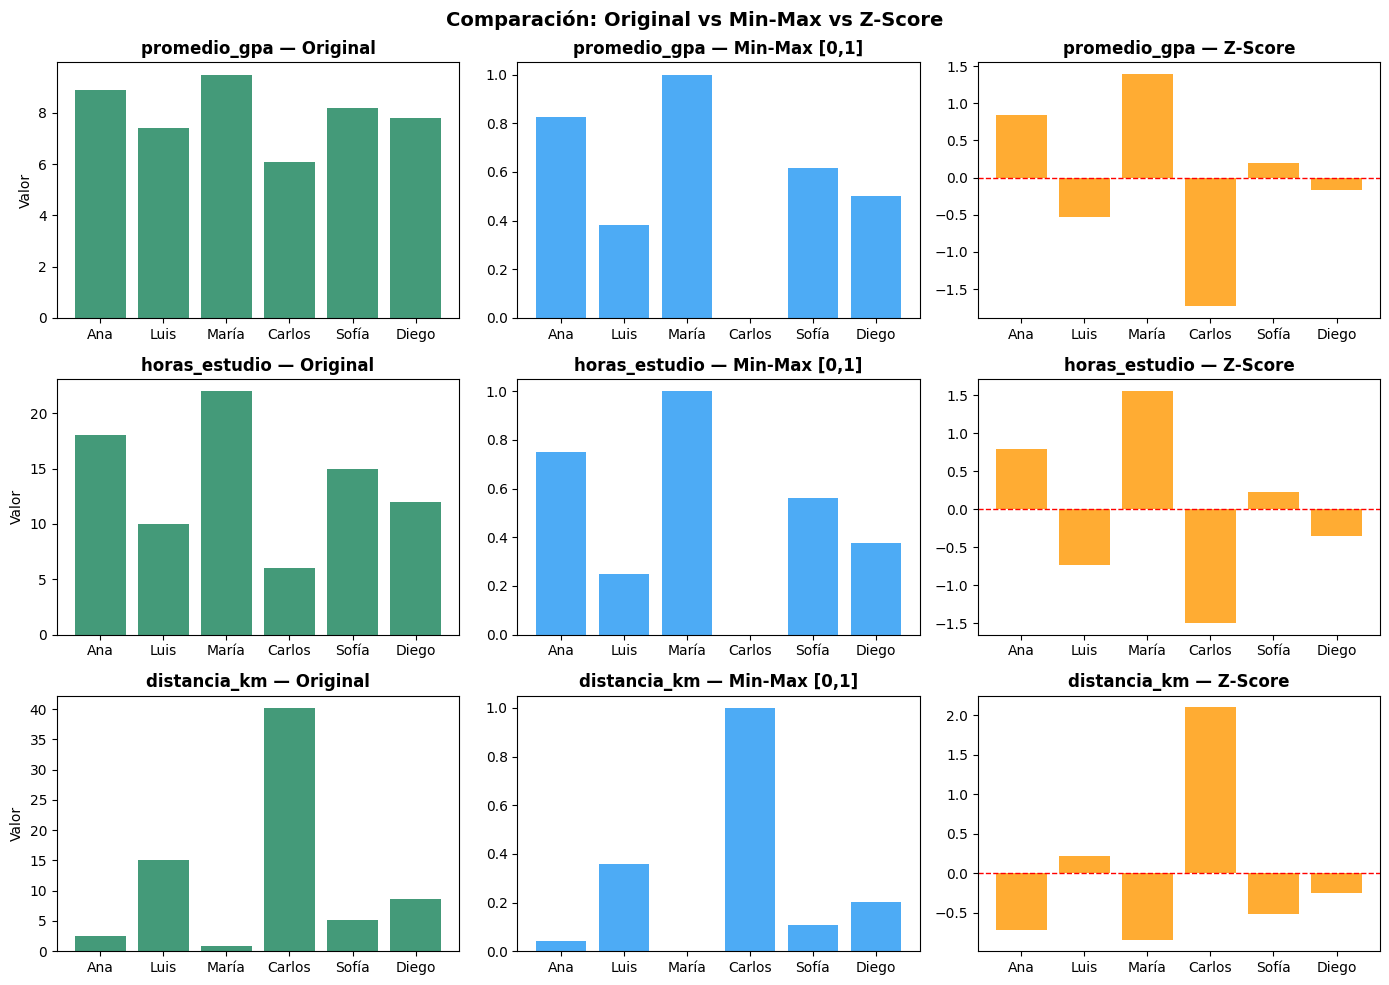

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
nombres = df["nombre"].values

for i, col in enumerate(columnas_numericas):
    # Original
    axes[i, 0].bar(nombres, X[:, i], color="#158158", alpha=0.8)
    axes[i, 0].set_title(f"{col} — Original", fontweight='bold')
    axes[i, 0].set_ylabel("Valor")

    # Min-Max
    axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3", alpha=0.8)
    axes[i, 1].set_title(f"{col} — Min-Max [0,1]", fontweight='bold')

    # Z-Score
    axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800", alpha=0.8)
    axes[i, 2].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[i, 2].set_title(f"{col} — Z-Score", fontweight='bold')

plt.suptitle("Comparación: Original vs Min-Max vs Z-Score", fontsize=14,
             fontweight='bold')
plt.tight_layout()
plt.savefig("comparacion_escalado.png", dpi=100)
plt.show()

**P14. Observa la gráfica de distancia_km. Las proporciones relativas entre estudiantes, ¿se mantienen igual en las tres versiones? ¿Qué es lo que realmente cambia entre Original, Min-Max y Z-Score?**

*Respuesta:* Si, el orden y la forma de las barras se mantienen igual en las tres versiones: Carlos sigue siendo el que vive mas lejos y María la que vive mas cerca, y las distancias entre ellos se ven igual. Lo que cambia es la escala del eje Y: en Original esta en km, en Min-Max va de 0 a 1 y en Z-Score esta centrado en 0, donde los negativos estan por debajo de la media y los positivos por encima.

## Actividad 2.5:

### Simulando un outlier extremo

In [ ]:
# Añadimos un estudiante con una distancia extrema
X_con_outlier = np.vstack([X, [8.5, 14, 120.0]])  # 120 km

# Aplicamos Min-Max sobre los datos CON outlier
X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)

# Aplicamos Z-Score sobre los datos CON outlier
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

print("=== Columna distancia_km con outlier (120 km) ===")
print(f"\n{'Estudiante':<10} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 44)
nombres_ext = list(nombres) + ["Nuevo"]
for j in range(len(nombres_ext)):
    print(f"{nombres_ext[j]:<10} {X_con_outlier[j,2]:>10.1f} "
          f"{X_mm_con_outlier[j,2]:>10.4f} {X_z_con_outlier[j,2]:>10.4f}")

=== Columna distancia_km con outlier (120 km) ===

Estudiante   Original    Min-Max    Z-Score
--------------------------------------------
Ana               2.5     0.0143    -0.6280
Luis             15.0     0.1191    -0.3137
María             0.8     0.0000    -0.6708
Carlos           40.2     0.3305     0.3201
Sofía             5.1     0.0361    -0.5626
Diego             8.7     0.0663    -0.4721
Nuevo           120.0     1.0000     2.3271


**P15. Observa lo que ocurre con los valores de los otros estudiantes en Min-Max después de agregar el outlier de 120 km. ¿Qué problema genera esto? ¿Por qué Z-Score es más robusto ante este caso? ¿Existe alguna técnica mejor aún?**

*Respuesta:* Con el outlier de 120 km, los demas estudiantes quedan aplastados cerca de 0 (de Ana a Diego estan entre 0.0 y 0.12), e incluso Carlos bajo de 1.0 a 0.3305. El problema es que se pierde la diferencia entre ellos, porque casi todo el rango lo ocupa un solo valor. Z-Score es mas robusto porque no depende solo del min y max, sino de la media y la desviacion de todos los datos. Aunque tampoco es perfecto, porque la media y la desviacion tambien se ven afectadas por el outlier (Carlos paso de 2.0997 a 0.3201). Una tecnica mejor es el RobustScaler, que usa la mediana y el IQR, que casi no cambian con valores extremos.

# FASE 3. Dataset real con Pandas: Palmer Penguins

Ahora trabajarás con un dataset real de Hugging Face. El dataset [Palmer Penguins](https://huggingface.co/datasets/SIH/palmer-penguins), creado originalmente como paquete de R, fue diseñado para reemplazar al famoso Iris dataset en tareas de exploración y visualización de datos.

In [ ]:
import pandas as pd

# Cargamos el dataset directamente desde Hugging Face
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)

print("=== PRIMERA VISTA DEL DATASET ===")
print(df_penguins.head(8))
print(f"\nDimensiones: {df_penguins.shape}")
print(f"\nColumnas: {list(df_penguins.columns)}")

=== PRIMERA VISTA DEL DATASET ===
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   
6  Adelie  Torgersen            38.9           17.8              181.0   
7  Adelie  Torgersen            39.2           19.6              195.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  
5       3650.0    male  2007  
6       3625.0  female  2007  
7       4675.0    male  2007  

Dimensiones: (344, 

## Actividad 3.1:

### Exploración inicial obligatoria

In [ ]:
print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)

print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())

print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_penguins.describe())

print("\n=== VALORES ÚNICOS EN COLUMNAS CATEGÓRICAS ===")
for col in df_penguins.select_dtypes(include='object').columns:
    print(f"{col}: {df_penguins[col].unique()}")


=== TIPOS DE DATOS ===
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

=== VALORES NULOS ===
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

=== ESTADÍSTICAS DESCRIPTIVAS ===
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  \
count      342.000000     342.000000         342.000000   342.000000   
mean        43.921930      17.151170         200.915205  4201.754386   
std          5.459584       1.974793          14.061714   801.954536   
min         32.100000      13.100000         172.000000  2700.000000   
25%         39.225000      15.600000         190.000000  3550.000000   
50%         44.450000      17.30000

**P16. Identifica para este dataset: ¿cuántas instancias tiene? ¿Cuáles son las features numéricas? ¿Cuál sería el label más lógico para una tarea de clasificación?**

*Respuesta:* El dataset tiene 344 instancias. Las features numericas son bill_length_mm, bill_depth_mm, flipper_length_mm y body_mass_g. year tambien es numerica, pero solo indica el año en que se tomo el dato, no es una caracteristica del pingüino. El label mas logico seria species, porque el objetivo seria predecir la especie (Adelie, Gentoo o Chinstrap) a partir de sus medidas.

**P17. ¿Hay valores nulos? ¿En qué columnas? ¿Por qué es importante tratar los valores nulos antes de aplicar escalado? ¿Qué pasaría si escalas con NaN presentes?**

*Respuesta:* Si, hay valores nulos. bill_length_mm, bill_depth_mm, flipper_length_mm y body_mass_g tienen 2 cada una, y sex tiene 11. Es importante tratarlos antes porque el escalado necesita calcular el min, max, media o desviacion de cada columna, y un NaN no es un numero con el que se pueda operar. Si se escala con NaN, en NumPy cualquier operacion con NaN da NaN, por lo que el min o la media de la columna saldria NaN y todos los valores transformados se dañarian. sklearn ignora los NaN al calcular, pero los deja en el resultado y el modelo despues falla al entrenar.

## Actividad 3.2:

### Clasificación de variables del dataset

**P18. Para cada columna de df_penguins, clasifica su tipo completo. Presta especial atención a sex e island. ¿Son las dos nominales? ¿Cambiaría la respuesta si ordenamos las islas por temperatura promedio del océano?**

*Respuesta:* - species: cualitativa nominal
- island: cualitativa nominal
- bill_length_mm: cuantitativa continua
- bill_depth_mm: cuantitativa continua
- flipper_length_mm: cuantitativa continua
- body_mass_g: cuantitativa continua
- sex: cualitativa nominal
- year: cuantitativa discreta

Si, sex e island son nominales porque no tienen un orden: ser male o female, o vivir en Biscoe o Dream, no es mayor ni menor que lo otro. Si ordenamos las islas por temperatura promedio del oceano, island pasaria a ser ordinal, porque ya existiria un criterio que pone una isla antes que otra. Aunque ese orden no viene de la variable en si, sino de otro dato (la temperatura).

## Actividad 3.3:

### Preprocesamiento y escalado

In [ ]:
# Paso 1: Eliminar filas con valores nulos
df_clean = df_penguins.dropna()
print(f"Filas originales: {len(df_penguins)} → Filas limpias: {len(df_clean)}")

# Paso 2: Seleccionar features numéricas
features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]
X_penguins = df_clean[features_num].values

print("\nEstadísticas ANTES del escalado:")
print(pd.DataFrame(X_penguins, columns=features_num).describe().round(2))

Filas originales: 344 → Filas limpias: 333

Estadísticas ANTES del escalado:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


**P19. Mira las escalas de body_mass_g (en gramos, ~3500–6000) vs bill_depth_mm (en mm, ~13–21). Si entrenas un modelo con estos datos sin escalar, ¿cuál variable tendrá más peso en el cálculo de distancia? ¿Es eso justo biológicamente?**

*Respuesta:* body_mass_g tendria mucho mas peso, porque sus valores estan en miles y la diferencia entre dos pingüinos puede ser de cientos o miles de gramos, mientras que en bill_depth_mm la diferencia es de unos pocos milimetros. No es justo biologicamente, porque el modelo le daria mas importancia al peso solo por estar medido en gramos, no porque sea mas importante para diferenciar a los pingüinos. Si el peso estuviera en kg pasaria lo contrario.

## Actividad 3.4:

### Análisis de distribuciones

In [ ]:
# Paso 3: Aplicar Min-Max
mm = MinMaxScaler()
X_mm = mm.fit_transform(X_penguins)

# Paso 4: Aplicar Z-Score
zs = StandardScaler()
X_zs = zs.fit_transform(X_penguins)

# Paso 5: Comparar estadísticas
print("\n--- Min-Max ---")
print(pd.DataFrame(X_mm, columns=features_num).describe().round(4))

print("\n--- Z-Score ---")
print(pd.DataFrame(X_zs, columns=features_num).describe().round(4))


--- Min-Max ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean           0.4325         0.4839             0.4910       0.4186
std            0.1989         0.2344             0.2376       0.2237
min            0.0000         0.0000             0.0000       0.0000
25%            0.2691         0.2976             0.3051       0.2361
50%            0.4509         0.5000             0.4237       0.3750
75%            0.6000         0.6667             0.6949       0.5764
max            1.0000         1.0000             1.0000       1.0000

--- Z-Score ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean          -0.0000        -0.0000             0.0000      -0.0000
std            1.0015         1.0015             1.0015       1.0015
min           -2.1780        -2.0673            -2.0699      -1.8744


Media: 4207.06 | Mediana: 4050.00


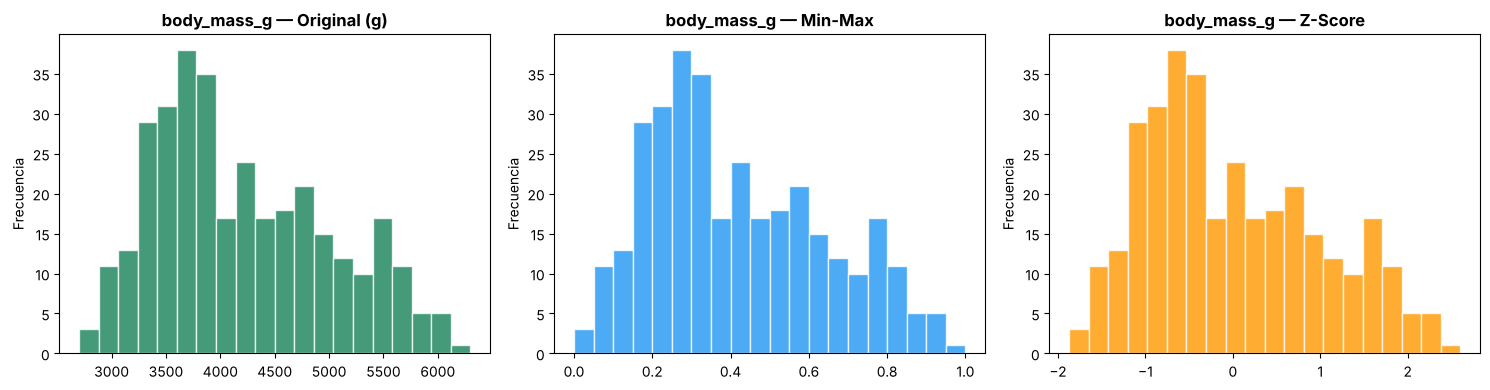

In [ ]:
# Histogramas de body_mass_g (columna 3) para responder P20 y P21
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
versiones = [(X_penguins[:, 3], "Original (g)", "#158158"),
             (X_mm[:, 3], "Min-Max", "#2196F3"),
             (X_zs[:, 3], "Z-Score", "#FF9800")]

for ax, (valores, titulo, color) in zip(axes, versiones):
    ax.hist(valores, bins=20, color=color, alpha=0.8, edgecolor="white")
    ax.set_title(f"body_mass_g — {titulo}", fontweight="bold")
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

print(f"Media: {X_penguins[:, 3].mean():.2f} | Mediana: {np.median(X_penguins[:, 3]):.2f}")

**P20. ¿El escalado cambia la forma de la distribución (histograma) o solo la escala de los ejes? ¿Por qué importa esa respuesta cuando evaluamos normalidad de los datos?**

*Respuesta:* El escalado solo cambia la escala de los ejes, la forma del histograma es la misma, como se ve en las tres graficas de body_mass_g. Esto importa porque si los datos no son normales antes de escalar, tampoco lo seran despues. Z-Score deja media 0 y desviacion 1, pero eso no convierte a los datos en una distribucion normal.

**P21. Observa la distribución de body_mass_g. ¿Se parece a una campana de Gauss (distribución normal) o tiene alguna asimetría? ¿Afecta eso a la elección entre Min-Max y Z-Score?**

*Respuesta:* No se parece a una campana de Gauss, tiene asimetria hacia la derecha: la mayoria de pingüinos esta entre 3300 y 3900 g y hay una cola hacia los valores altos. Tambien se ve en que la media (4207) es mayor que la mediana (4050). Posiblemente es porque hay una especie mas pesada que las otras (Gentoo). Si afecta un poco, porque Z-Score funciona mejor cuando los datos son mas o menos normales, y Min-Max depende del maximo, que aqui esta en la cola. Como no hay outliers extremos, cualquiera de los dos se puede usar, pero ninguno corrige la asimetria.

# FASE 4: HuggingFace + sklearn

En la fase anterior implementaste Min-Max y Z-Score desde cero con NumPy. Ahora vas a reproducir exactamente los mismos resultados usando sklearn, y añadirás un tercer método que no puedes implementar tan fácilmente a mano: el Robust Scaler. El dataset sigue siendo Palmer Penguins, que ya conoces.

## Actividad 4.1:

### Retornando al dataset limpio

Asegúrate de tener el DataFrame `df_clean` y las columnas `features_num` de la Fase 3. Si reiniciaste el kernel, ejecuta esto:

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
df_clean = df_penguins.dropna()

features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]

X = df_clean[features_num].values

print(f"Dataset listo: {X.shape[0]} instancias, {X.shape[1]} features")
print(f"\nEstadísticas originales:")
print(pd.DataFrame(X, columns=features_num).describe().round(2))

Dataset listo: 333 instancias, 4 features

Estadísticas originales:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


**P22. Antes de continuar: ¿cuál de las cuatro features tiene mayor rango (max − min)? ¿Cuál tiene menor rango? Calcula ambos valores con código y anótalos, los vas a necesitar para comparar después.**

In [ ]:
# Rango (max - min) de cada feature
rangos = X.max(axis=0) - X.min(axis=0)

for col, r in zip(features_num, rangos):
    print(f"{col:<18} rango = {r}")

# np.argmax / np.argmin devuelven la posición del mayor y menor rango
print(f"\nMayor rango: {features_num[np.argmax(rangos)]} ({rangos.max()})")
print(f"Menor rango: {features_num[np.argmin(rangos)]} ({rangos.min()})")

bill_length_mm     rango = 27.5
bill_depth_mm      rango = 8.4
flipper_length_mm  rango = 59.0
body_mass_g        rango = 3600.0

Mayor rango: body_mass_g (3600.0)
Menor rango: bill_depth_mm (8.4)


*Respuesta:* body_mass_g tiene el mayor rango con 3600 g (de 2700 a 6300) y bill_depth_mm tiene el menor con 8.4 mm (de 13.1 a 21.5). Los otros dos son bill_length_mm con 27.5 y flipper_length_mm con 59.

## Actividad 4.2:

### División train/test. Antes de escalar, el dataset debe dividirse. Este orden no es opcional.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(
    X,
    test_size=0.2,       # 80% entrenamiento, 20% prueba
    random_state=42      # fija la aleatoriedad para reproducibilidad
)

print(f"Train: {X_train.shape} → {X_train.shape[0]} pingüinos")
print(f"Test:  {X_test.shape}  → {X_test.shape[0]} pingüinos")

Train: (266, 4) → 266 pingüinos
Test:  (67, 4)  → 67 pingüinos


**P23. ¿Por qué se divide el dataset antes de aplicar el escalado y no después? Piensa en qué información usaría el scaler si lo aplicaras primero sobre todo el dataset. ¿Qué datos del test estarías "filtrando" al proceso de entrenamiento? Esto se llama data leakage; explícalo con tus propias palabras.**

*Respuesta:* Se divide antes porque el scaler aprende parametros de los datos (min, max, media, desviacion). Si lo aplico sobre todo el dataset, esos parametros incluirian a los datos del test, por lo que el modelo ya tendria informacion del test antes de ser evaluado. Por ejemplo, si el pingüino mas pesado esta en el test, el max que usa el scaler saldria de ese pingüino. El data leakage es cuando informacion del test se "filtra" al entrenamiento, y hace que el modelo parezca mejor de lo que realmente es, porque el test ya no son datos totalmente nuevos.

## Actividad 4.3:

### Aplicando los tres escaladores. El patrón de uso es siempre el mismo:

- `fit_transform(X_train)` → aprende los parámetros del train y lo transforma
- `transform(X_test)` → aplica los mismos parámetros aprendidos al test, sin recalcularlos

In [ ]:
# Instanciar los tres escaladores
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()

# Aplicar a train: fit + transform
X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)

# Aplicar a test: solo transform (NO fit)
X_test_mm = mm_scaler.transform(X_test)
X_test_zs = zs_scaler.transform(X_test)
X_test_rb = rb_scaler.transform(X_test)

print("Parámetros aprendidos por MinMaxScaler (sobre train):")
print(f"  Mínimos:  {mm_scaler.data_min_.round(2)}")
print(f"  Máximos:  {mm_scaler.data_max_.round(2)}")

print("\nParámetros aprendidos por StandardScaler (sobre train):")
print(f"  Medias:   {zs_scaler.mean_.round(2)}")
print(f"  Std:      {zs_scaler.scale_.round(2)}")

print("\nParámetros aprendidos por RobustScaler (sobre train):")
print(f"  Medianas: {rb_scaler.center_.round(2)}")
print(f"  IQR:      {rb_scaler.scale_.round(2)}")

Parámetros aprendidos por MinMaxScaler (sobre train):
  Mínimos:  [  32.1   13.1  172.  2700. ]
  Máximos:  [  59.6   21.5  231.  6050. ]

Parámetros aprendidos por StandardScaler (sobre train):
  Medias:   [  44.08   17.07  201.41 4232.61]
  Std:      [  5.41   1.97  14.24 809.57]

Parámetros aprendidos por RobustScaler (sobre train):
  Medianas: [  44.9   17.2  197.  4100. ]
  IQR:      [   8.9    3.2   24.  1200. ]


**P22. Compara los parámetros que aprendió MinMaxScaler (mínimos y máximos) con los que calculaste manualmente en la Fase 2 con NumPy. ¿Son exactamente iguales o hay alguna diferencia pequeña? ¿A qué se debe si la hay?**

*Respuesta:* En la Fase 2 se uso el dataset de estudiantes, asi que compare con los min y max del dataset completo de pingüinos de la actividad 4.1. Los minimos son iguales, y los maximos tambien excepto body_mass_g: con el dataset completo es 6300 y con el train es 6050. La diferencia se debe a que MinMaxScaler solo aprendio del train (80%), y el pingüino de 6300 g quedo en el test.

**P23. El RobustScaler aprende la mediana y el IQR de cada columna, no la media ni el std. Calcula manualmente la mediana y el IQR de body_mass_g en el train con NumPy y verifica que coincidan con rb_scaler.center_[3] y rb_scaler.scale_[3].**

In [ ]:
# Columna 3 = body_mass_g, solo del train
body_train = X_train[:, 3]

mediana = np.median(body_train)
q1 = np.percentile(body_train, 25)   # primer cuartil
q3 = np.percentile(body_train, 75)   # tercer cuartil
iqr = q3 - q1

print(f"Q1 = {q1} | Q3 = {q3}")
print(f"Mediana manual: {mediana} | RobustScaler: {rb_scaler.center_[3]}")
print(f"IQR manual:     {iqr} | RobustScaler: {rb_scaler.scale_[3]}")
print("¿Coinciden?", np.isclose(mediana, rb_scaler.center_[3]) and np.isclose(iqr, rb_scaler.scale_[3]))

Q1 = 3600.0 | Q3 = 4800.0
Mediana manual: 4100.0 | RobustScaler: 4100.0
IQR manual:     1200.0 | RobustScaler: 1200.0
¿Coinciden? True


*Respuesta:* La mediana de body_mass_g en el train es 4100 g y el IQR es 1200 g (Q3 = 4800 menos Q1 = 3600). Ambos coinciden con rb_scaler.center_[3] y rb_scaler.scale_[3], lo que confirma que RobustScaler resta la mediana y divide para el IQR.